# (1)

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

#Do not want to tamper on the base data. 
#We'll save the changes in a new .csv file as one of the final steps.
birdstrikes_raw = pd.read_csv('../birdstrikes.csv', parse_dates=['Flight Date'])
birdstrikes = birdstrikes_raw.copy()

#Table size. (Should be 10000, 14)
print(f'Size/shape: {birdstrikes.shape}')

#Columns.
print(f'Columns: {list(birdstrikes.columns.values)}')

#General idea of the actual values we'll be dealing with.
print(birdstrikes.value_counts().head(10))

#These first 10 entries have 0 on three columns, being: Cost Other, Cost Repair, and Cost Total.
#Therefore, we'll conduct a quick check if this applies for all other entries as well.
print(len(birdstrikes[birdstrikes['Cost Other'] == 0])) #Count: 9928
print(len(birdstrikes[birdstrikes['Cost Repair'] == 0])) #Count: 9822
print(len(birdstrikes[birdstrikes['Cost Total $'] == 0])) #Count: 9791

Size/shape: (10000, 14)
Columns: ['Airport Name', 'Aircraft Make Model', 'Effect Amount of damage', 'Flight Date', 'Aircraft Airline Operator', 'Origin State', 'Phase of flight', 'Wildlife Size', 'Wildlife Species', 'Time of day', 'Cost Other', 'Cost Repair', 'Cost Total $', 'Speed IAS in knots']
Airport Name                    Aircraft Make Model  Effect Amount of damage  Flight Date  Aircraft Airline Operator  Origin State  Phase of flight  Wildlife Size  Wildlife Species       Time of day  Cost Other  Cost Repair  Cost Total $  Speed IAS in knots
NEW ORLEANS INTL                B-737-300            Substantial              1990-01-11   SOUTHWEST AIRLINES         Louisiana     Take-off run     Small          Rock pigeon            Day          0           0            0             140.0                 1
WASHINGTON DULLES INTL ARPT     BA-146               Medium                   1990-03-03   AIR WISCONSIN AIRLINES     DC            Climb            Large          Unknown bird - la

Seen in its entirety, a row describes the circumstances of the flight through a handful of different day:
What type of flight from where, and when the incident happened both in terms of day/night and flight phase.

Most values do not have any specified costs, between about 0.5-2.0% of the entries have anything beyond 0.
The zeroes do not have to mean a cost was never inserted, but actually that no cost to fix the plane in any way was needed.
Since there are birds, it is highly unlikely that any of them would weigh more than a human, and
collision between a human and a plane would highly likely and realistically only cause harm to the human in most likely.

We'll keep these values; they could be outliers of further interest.

# (2)

In [3]:
#To know if something could be incorrect, it can be smart to first get what datatypes there are.
birdstrikes.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Airport Name               10000 non-null  str           
 1   Aircraft Make Model        10000 non-null  str           
 2   Effect Amount of damage    1061 non-null   str           
 3   Flight Date                10000 non-null  datetime64[us]
 4   Aircraft Airline Operator  10000 non-null  str           
 5   Origin State               10000 non-null  str           
 6   Phase of flight            10000 non-null  str           
 7   Wildlife Size              10000 non-null  str           
 8   Wildlife Species           10000 non-null  str           
 9   Time of day                10000 non-null  str           
 10  Cost Other                 10000 non-null  int64         
 11  Cost Repair                10000 non-null  int64         
 12  Cost Total $    

**Speed IAS in knots** has 7164 non-null entries. 
**Effect amount of damage** has 1061 non-null entries; worth investigating.

Another point of curiosity is why only one of the Cost columns have a $ in it: **Cost Total \$**. 

In [4]:
#How many entries that are duplicates in the eyes of each other, 
#and how many duplicates there are (ignoring the first entry found).
print(birdstrikes.duplicated(keep=False).sum())
print(birdstrikes.duplicated().sum())

birdstrikes[birdstrikes.duplicated()]

45
24


,Airport Name,Aircraft Make Model,Effect Amount of damage,Flight Date,Aircraft Airline Operator,Origin State,Phase of flight,Wildlife Size,Wildlife Species,Time of day,Cost Other,Cost Repair,Cost Total $,Speed IAS in knots
341,ATLANTIC CITY INTL,F-16,NaN,1990-10-15,MILITARY,New Jersey,Landing Roll,Medium,Unknown bird or bat,Night,0,0,0,0.0
1114,BARKSDALE AIR FORCE BASE ARPT,KC-10A,NaN,1992-04-14,MILITARY,Louisiana,Approach,Medium,Unknown bird or bat,Night,0,0,0,150.0
1132,BARKSDALE AIR FORCE BASE ARPT,KC-10A,NaN,1992-04-23,MILITARY,Louisiana,Approach,Medium,Unknown bird or bat,Night,0,0,0,140.0
1268,GREATER PITTSBURGH,DC-9-30,NaN,1992-06-15,US AIRWAYS*,Pennsylvania,Climb,Small,Unknown bird - small,Day,0,0,0,150.0
1814,BARKSDALE AIR FORCE BASE ARPT,KC-10A,NaN,1993-04-28,MILITARY,Louisiana,Approach,Medium,Unknown bird or bat,Night,0,0,0,180.0
2081,CHARLESTON AFB/INTL ARPT,C-141B,NaN,1993-08-18,MILITARY,South Carolina,Climb,Medium,Unknown bird or bat,Day,0,0,0,130.0
2897,CHARLESTON AFB/INTL ARPT,C-141B,NaN,1994-10-10,MILITARY,South Carolina,Approach,Medium,Unknown bird or bat,Night,0,0,0,160.0
3043,HONOLULU INTL ARPT,C-141,NaN,1995-01-10,MILITARY,Hawaii,Approach,Medium,Unknown bird - medium,Day,0,0,0,128.0
6190,CHARLESTON AFB/INTL ARPT,C-17A,NaN,1998-11-04,MILITARY,South Carolina,Approach,Medium,Unknown bird or bat,Night,0,0,0,230.0
6236,CHARLESTON AFB/INTL ARPT,C-17A,NaN,1998-12-04,MILITARY,South Carolina,Approach,Medium,Unknown bird or bat,Day,0,0,0,130.0


The duplicates that are identical on all columns will not give any new insights to us.
It is way too unlikely that entries matching on everything, from model, airport AND collision time, would happen.
We'll start off by deleting these.

In [5]:
#keep is 'first' by default, so we do not specify anything.
birdstrikes = birdstrikes.drop_duplicates(keep='first')

#Count as a safety measure.
print(birdstrikes.duplicated().sum())

0


Most birdstrikes have reoccurring aircraft models, based on the fact that this gives 9751 Trues.

In [6]:
birdstrikes.duplicated(subset = 'Aircraft Make Model').value_counts()

True     9751
False     225
Name: count, dtype: int64

A sample used as a check - that does not however answer about the entire dataset - shows that entries with the same models do not 
have too identical values over all the columns.

In [7]:
birdstrikes[birdstrikes.duplicated(subset = 'Aircraft Make Model')].head(20)

,Airport Name,Aircraft Make Model,Effect Amount of damage,Flight Date,Aircraft Airline Operator,Origin State,Phase of flight,Wildlife Size,Wildlife Species,Time of day,Cost Other,Cost Repair,Cost Total $,Speed IAS in knots
4,BARKSDALE AIR FORCE BASE ARPT,KC-10A,NaN,1990-01-12,MILITARY,Louisiana,Climb,Medium,Unknown bird or bat,Day,0,0,0,160.0
5,BARKSDALE AIR FORCE BASE ARPT,KC-10A,NaN,1990-02-02,MILITARY,Louisiana,Take-off run,Medium,Unknown bird or bat,Day,0,0,0,180.0
6,BARKSDALE AIR FORCE BASE ARPT,KC-10A,NaN,1990-02-06,MILITARY,Louisiana,Climb,Medium,Unknown bird or bat,Dusk,0,0,0,140.0
8,BARKSDALE AIR FORCE BASE ARPT,KC-10A,NaN,1990-03-01,MILITARY,Louisiana,Climb,Medium,Unknown bird or bat,Day,0,0,0,180.0
9,BARKSDALE AIR FORCE BASE ARPT,B-52,NaN,1990-03-02,MILITARY,Louisiana,Take-off run,Medium,Unknown bird or bat,Dusk,0,0,0,130.0
11,BARKSDALE AIR FORCE BASE ARPT,B-52,NaN,1990-03-08,MILITARY,Louisiana,Approach,Medium,Unknown bird or bat,Night,0,0,0,150.0
13,CHARLESTON AFB/INTL ARPT,C-141B,NaN,1990-03-09,MILITARY,South Carolina,Approach,Medium,Unknown bird or bat,Night,0,0,0,190.0
14,BARKSDALE AIR FORCE BASE ARPT,B-52,NaN,1990-03-09,MILITARY,Louisiana,Take-off run,Medium,Unknown bird or bat,Night,0,0,0,150.0
16,BARKSDALE AIR FORCE BASE ARPT,KC-10A,NaN,1990-03-19,MILITARY,Louisiana,Approach,Medium,Unknown bird or bat,Dusk,0,0,0,150.0
18,BARKSDALE AIR FORCE BASE ARPT,KC-10A,NaN,1990-04-04,MILITARY,Louisiana,Approach,Medium,Unknown bird or bat,Night,0,0,0,135.0


We can see that these few outliers in terms of classification, which we by ourselves cannot decode, pull the mean up a lot.
Looking at how much they add upp together, and in isolation, the mean gets skewed.
Although they would be of interesting consideration, we cannot say for sure what they are, and they 
make the others we do understand less valuable in comparison. 

Since they become noise for our case, we'll remove them (FOR NOW).
NOTE: This might be an incorrect way to treat this data, and so this may be looked over again later on.

In [8]:
birdstrikes['Effect Amount of damage'].value_counts(dropna=False)

Effect Amount of damage
NaN            8916
Minor           548
Substantial     311
Medium          186
C                14
B                 1
Name: count, dtype: int64

In [9]:
birdstrikes[
    birdstrikes['Effect Amount of damage'].isin(['B', 'C'])
]

,Airport Name,Aircraft Make Model,Effect Amount of damage,Flight Date,Aircraft Airline Operator,Origin State,Phase of flight,Wildlife Size,Wildlife Species,Time of day,Cost Other,Cost Repair,Cost Total $,Speed IAS in knots
299,ATLANTIC CITY INTL,C-137C,C,1990-09-26,MILITARY,New Jersey,Climb,Medium,Unknown bird - medium,Day,0,23656,23656,150.0
441,BARKSDALE AIR FORCE BASE ARPT,B-52G,C,1990-11-30,MILITARY,Louisiana,Climb,Small,Cattle egret,Day,0,67435,67435,175.0
598,BARKSDALE AIR FORCE BASE ARPT,B-52G,C,1991-05-14,MILITARY,Louisiana,Approach,Large,Turkey vulture,Day,0,160764,160764,140.0
648,CHARLESTON AFB/INTL ARPT,C-141B,C,1991-06-22,MILITARY,South Carolina,Approach,Medium,Unknown bird or bat,Day,0,37234,37234,200.0
1493,GREATER PITTSBURGH,KC-135E,C,1992-09-12,MILITARY,Pennsylvania,Approach,Medium,Unknown bird - medium,Day,0,117399,117399,200.0
2543,ATLANTIC CITY INTL,F-16,C,1994-05-19,MILITARY,New Jersey,Approach,Medium,Unknown bird - medium,Day,0,20439,20439,180.0
3381,CHARLESTON AFB/INTL ARPT,C-17A,C,1995-08-04,MILITARY,South Carolina,Approach,Medium,Unknown bird or bat,Day,0,69282,69282,230.0
5270,BARKSDALE AIR FORCE BASE ARPT,B-52H,C,1997-11-07,MILITARY,Louisiana,Approach,Medium,Unknown bird or bat,Dusk,0,21514,21514,155.0
5753,BARKSDALE AIR FORCE BASE ARPT,B-52H,C,1998-07-30,MILITARY,Louisiana,Approach,Large,Great blue heron,Night,0,21360,21360,150.0
7407,CHARLESTON AFB/INTL ARPT,C-17A,C,2000-04-24,MILITARY,South Carolina,Climb,Medium,Unknown bird or bat,Day,0,32073,32073,NaN


In [10]:
#All: Mean is ~2051.7
birdstrikes[birdstrikes['Aircraft Airline Operator'] == 'MILITARY']['Cost Total $'].agg(['mean', 'median'])

mean      2051.683047
median       0.000000
Name: Cost Total $, dtype: float64

In [11]:
#Without the unclear classifications: Mean drops to ~186
print(
    birdstrikes[
        (birdstrikes['Aircraft Airline Operator'] == 'MILITARY') &
        (~birdstrikes['Effect Amount of damage'].isin(['B', 'C']))
    ]['Cost Total $'].agg(['mean', 'median'])
)

#B: Mean is ~1271.4
print(
    birdstrikes[
        (birdstrikes['Aircraft Airline Operator'] == 'MILITARY') &
        (~birdstrikes['Effect Amount of damage'].isin(['B']))
    ]['Cost Total $'].agg(['mean', 'median'])
)

#C: Mean is ~981.3
print(
    birdstrikes[
        (birdstrikes['Aircraft Airline Operator'] == 'MILITARY') &
        (~birdstrikes['Effect Amount of damage'].isin(['C']))
    ]['Cost Total $'].agg(['mean', 'median'])
)

mean      186.006258
median      0.000000
Name: Cost Total $, dtype: float64
mean      1271.420664
median       0.000000
Name: Cost Total $, dtype: float64
mean      981.28
median      0.00
Name: Cost Total $, dtype: float64


Removal of B and C.

In [12]:
birdstrikes = birdstrikes.drop(birdstrikes[birdstrikes['Effect Amount of damage'].isin(['B', 'C'])].index)

Check that they are removed. (Only ones existing now are 'Substantial', 'Medium', 'Minor')

In [13]:
birdstrikes['Effect Amount of damage'].unique()

<StringArray>
[nan, 'Substantial', 'Medium', 'Minor']
Length: 4, dtype: str

To check if there could be any correlation between the Cost columns, before we change the name of the Cost Final $ column,
we'll check different values with an aggregation.

In [14]:
birdstrikes.groupby('Effect Amount of damage')[['Cost Other', 'Cost Repair', 'Cost Total $']].agg(['mean', 'median'])

Cost Other           Cost Repair         \
                                 mean median           mean median   
Effect Amount of damage                                              
Medium                     780.634409    0.0    4555.000000    0.0   
Minor                     1106.395985    0.0    3812.728102    0.0   
Substantial              10823.922830    0.0  101912.070740    0.0   

                          Cost Total $         
                                  mean median  
Effect Amount of damage                        
Medium                     5335.634409    0.0  
Minor                      4919.124088    0.0  
Substantial              112735.993569    0.0

0 results where Repair and Other do not add up to the Total.

In [15]:
birdstrikes[birdstrikes['Cost Total $'] != birdstrikes['Cost Other'] + birdstrikes['Cost Repair']]

,Airport Name,Aircraft Make Model,Effect Amount of damage,Flight Date,Aircraft Airline Operator,Origin State,Phase of flight,Wildlife Size,Wildlife Species,Time of day,Cost Other,Cost Repair,Cost Total $,Speed IAS in knots


The means in Other and Repair are the sum of Total. Safe to say that they do relate to each other, and we can rename the column.

In [16]:
birdstrikes = birdstrikes.rename(columns={'Cost Total $' : 'Cost Total'})

In [17]:
birdstrikes['Cost Total'].describe()

count    9.961000e+03
mean     3.917661e+03
std      1.020903e+05
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      7.043545e+06
Name: Cost Total, dtype: float64

Slight renaming of Effect Amount of damage to a few columns, while we're at it.

In [18]:
columns = {
    'Effect Amount of damage' : 'Effect Amount of Damage',
    'Phase of flight' : 'Phase of Flight',
    'Time of day' : 'Time of Day',
    'Speed IAS in knots' : 'Speed IAS in Knots'
}

birdstrikes = birdstrikes.rename(columns=columns)

In [19]:
birdstrikes.columns

Index(['Airport Name', 'Aircraft Make Model', 'Effect Amount of Damage',
       'Flight Date', 'Aircraft Airline Operator', 'Origin State',
       'Phase of Flight', 'Wildlife Size', 'Wildlife Species', 'Time of Day',
       'Cost Other', 'Cost Repair', 'Cost Total', 'Speed IAS in Knots'],
      dtype='str')

Lastly, we'll do cleanup on the names in columns **Airport Name** and **Aircraft Airline Operator**.
We already know here that a few exceptions, such as acronyms appear, and we'll deal with those after doing a general replacement treatment.

**Airport** in the name is redundant. International airports are usually called "International Airport" in actuality, 
which one does not specify. Will simply standardize these to be readable and without redundant contents.

In [20]:
birdstrikes['Airport Name'] = (
    birdstrikes['Airport Name']
    .str.title()
    .str.replace(
        {'Arpt' : '', 
        "Intl" : "International",
        'Natl' : 'National',
        'Laguardia Ny' : 'LaGuardia',
        '(Or)' : ''}
    )
    .str.strip()
)
birdstrikes['Airport Name'].unique()

<StringArray>
[                  'Barksdale Air Force Base',
                  'New Orleans International',
            'Washington Dulles International',
          'Ronald Reagan Washington National',
               'Charleston Afb/International',
             'Lambert-St Louis International',
                                  'LaGuardia',
            'Charlotte/Douglas International',
                  'Los Angeles International',
               'Chicago O'Hare International',
                     'Portland International',
    'Fort Lauderdale/Hollywood International',
                              'Houston-Hobby',
                  'San Antonio International',
                   'Sacramento International',
                          'Will Rogers World',
                      'Atlanta International',
                 'Indianapolis International',
            'Dallas/Fort Worth International',
                  'Kansas City International',
              'Mineta San Jose International',

In [21]:
birdstrikes['Aircraft Airline Operator'] = (
    birdstrikes['Aircraft Airline Operator']
    .str.title()
    .str.replace(
        {
            'Alleghenyairlines' : 'Allegheny Airlines', 'Expressjet (Continental Exprs)' : 'ExpressJet',
            '*' : '',
            'Us' : 'US', 'Fedex' : 'FedEx', 'Skywest' : 'SkyWest', 'Airtran' : 'AirTran',
            'Ups' : 'UPS', 'Abx' : 'ABX', 'Psa' : 'PSA'
        }
    )
)

birdstrikes['Aircraft Airline Operator'].unique()

<StringArray>
[               'Military',      'Southwest Airlines',
           'FedEx Express',  'Air Wisconsin Airlines',
   'Trans States Airlines',              'US Airways',
       'American Airlines',                 'Unknown',
         'United Airlines',         'Delta Air Lines',
                'Business',          'Aloha Airlines',
    'Trans World Airlines',              'ExpressJet',
            'UPS Airlines',            'PSA Airlines',
   'America West Airlines',    'Continental Airlines',
              'Government',      'Northwest Airlines',
         'Alaska Airlines',            'Hawaiian Air',
        'SkyWest Airlines',         'Comair Airlines',
             'Horizon Air',         'Mesaba Airlines',
              'Air Canada',         'Astar Air Cargo',
                'Pinnacle',      'Atlantic Southeast',
                 'ABX Air',      'Allegheny Airlines',
         'Privately Owned', 'American Eagle Airlines',
       'Piedmont Airlines',     'Chautauqua Airline

With this, we have cleaned everything up before we are looking at missing values.

# (3)

While for example Aircraft Airline Operator has Unknown in some entries, 
the ones we can see immediately having null entries are:

**Effect Amount of Damage** - 8916 entries
**Speed IAS in Knots** - 2829 entries

The values are of quite a substantial portion of all entries, so they will not be dropped, at least.
To be consistent with naming that has already been here, we'll fill the Effect Amount of Damage NaN entries with 'Unknown'.

In [22]:
#Count what is missing in every column. 
#The whole point here is 'keep', 'drop' or 'fill'.
birdstrikes.isnull().sum()

Airport Name                    0
Aircraft Make Model             0
Effect Amount of Damage      8916
Flight Date                     0
Aircraft Airline Operator       0
Origin State                    0
Phase of Flight                 0
Wildlife Size                   0
Wildlife Species                0
Time of Day                     0
Cost Other                      0
Cost Repair                     0
Cost Total                      0
Speed IAS in Knots           2829
dtype: int64

In [23]:
print(birdstrikes['Effect Amount of Damage'].value_counts(dropna=False))

birdstrikes['Effect Amount of Damage'] = (
    birdstrikes['Effect Amount of Damage'].fillna('Unknown')
)

print(birdstrikes['Effect Amount of Damage'].value_counts(dropna=False))

Effect Amount of Damage
NaN            8916
Minor           548
Substantial     311
Medium          186
Name: count, dtype: int64
Effect Amount of Damage
Unknown        8916
Minor           548
Substantial     311
Medium          186
Name: count, dtype: int64


This alone does not say very much. The definitely most normal values are in an interval between 120-160 knots.
So, we'll check them in relation to flight phase, (because the model names are basically cryptic enough for us to not get any value from them as directly).

In [24]:
birdstrikes['Speed IAS in Knots'].value_counts()

Speed IAS in Knots
140.0    971
130.0    625
150.0    528
120.0    470
160.0    422
        ... 
62.0       1
7.0        1
246.0      1
107.0      1
98.0       1
Name: count, Length: 122, dtype: int64

Since we do not want to delete any values, the two options we have now are "keep" or "fill". 
The fill would mean filling with the median, which would misrepresent Descent, Parked and Taxi. 
We'll keep them as NaN, so they do not skew the distribution more than necessary for us to make any interesting observations.

In [25]:
birdstrikes.groupby('Phase of Flight')['Speed IAS in Knots'].agg(['mean', 'median'])

,mean,median
Phase of Flight,,
Approach,152.921515,140.0
Climb,178.194754,167.0
Descent,232.032051,250.0
Landing Roll,111.422914,115.0
Parked,0.000000,0.0
Take-off run,122.786325,125.0
Taxi,41.750000,15.0


# (4)

A check on the Origin States before we do a merge.

In [26]:
print(birdstrikes['Origin State'].value_counts())

Origin State
Texas             1494
California         888
Louisiana          608
Tennessee          569
Kentucky           534
Pennsylvania       512
Illinois           505
DC                 475
New York           391
Missouri           374
Hawaii             351
New Jersey         347
North Carolina     269
Florida            246
Oregon             245
Utah               236
South Carolina     229
Georgia            210
Ohio               209
Maryland           201
Colorado           187
Massachusetts      146
Indiana            144
Nebraska           118
Arizona            111
Minnesota          103
Washington         102
Oklahoma            83
Michigan            74
Name: count, dtype: int64


In [27]:
us_regions_raw = pd.read_csv('../us_regions.csv')
us_regions = us_regions_raw.copy() 

Nothing is missing; now we just have another column (Region).

In [28]:
#Check shape of main table as it is, and check it after as well.
print(birdstrikes.shape)

birdstrikes = birdstrikes.merge(us_regions, on='Origin State', how='left')

print(birdstrikes.shape)

(9961, 14)
(9961, 15)


In [29]:
birdstrikes.columns

Index(['Airport Name', 'Aircraft Make Model', 'Effect Amount of Damage',
       'Flight Date', 'Aircraft Airline Operator', 'Origin State',
       'Phase of Flight', 'Wildlife Size', 'Wildlife Species', 'Time of Day',
       'Cost Other', 'Cost Repair', 'Cost Total', 'Speed IAS in Knots',
       'Region'],
      dtype='str')

Value checks after new column "Region" is added.

In [30]:
print(birdstrikes['Region'].value_counts())
print(len(birdstrikes))


Region
South        4918
West         2120
Midwest      1527
Northeast    1396
Name: count, dtype: int64
9961


In [31]:
#Same numbers as before on the Origin States? Yes: No difference on a single state.
print(birdstrikes['Origin State'].value_counts())

Origin State
Texas             1494
California         888
Louisiana          608
Tennessee          569
Kentucky           534
Pennsylvania       512
Illinois           505
DC                 475
New York           391
Missouri           374
Hawaii             351
New Jersey         347
North Carolina     269
Florida            246
Oregon             245
Utah               236
South Carolina     229
Georgia            210
Ohio               209
Maryland           201
Colorado           187
Massachusetts      146
Indiana            144
Nebraska           118
Arizona            111
Minnesota          103
Washington         102
Oklahoma            83
Michigan            74
Name: count, dtype: int64


# (5)

2 new columns:

- **Year**: Based on the Flight Date; quite straightforward.
- **Cost Category**: Bins based on Total.

In [32]:
birdstrikes['Year'] = birdstrikes['Flight Date'].dt.year

To divide the Cost Category, we will use describe() to look at the distribution of the values to divide the costs into bins/categories.

(Observation done with suggestion from: https://stackoverflow.com/questions/40347689/dataframe-describe-suppress-scientific-notation)

In [33]:
birdstrikes[birdstrikes['Cost Total'] != 0]['Cost Total'].describe().apply(lambda x: format(x, 'f'))

count        194.000000
mean      201153.737113
std       705678.588902
min           35.000000
25%         2318.500000
50%        20198.000000
75%        88939.250000
max      7043545.000000
Name: Cost Total, dtype: str

(Upper values: https://stackoverflow.com/questions/3477283/what-is-the-maximum-float-in-python)

In [34]:
birdstrikes['Cost Category'] = pd.cut(
    birdstrikes['Cost Total'],
    bins=[-1, 0, 5000, 50000, float("inf")],
    labels=['Zero Cost', 'Low Cost', 'Medium Cost', 'High Cost']
)

In [35]:
birdstrikes['Cost Category'].value_counts()

Cost Category
Zero Cost      9767
Medium Cost      65
High Cost        65
Low Cost         64
Name: count, dtype: int64

# (6)

**Groupby 1**: Reports per Year.

In [61]:
reports_per_year = birdstrikes.groupby('Year').size().reset_index(name='Reports')
print(reports_per_year)

    Year  Reports
0   1990      460
1   1991      569
2   1992      653
3   1993      675
4   1994      665
5   1995      711
6   1996      752
7   1997      864
8   1998      901
9   1999      937
10  2000     1060
11  2001     1089
12  2002      625


In [65]:
#Additional data for us to have percentual differences we can rely on later.
reports_1990 = reports_per_year[reports_per_year['Year'] == 1990]['Reports'].values[0]
reports_2001 = reports_per_year[reports_per_year['Year'] == 2001]['Reports'].values[0]
reports_2002 = reports_per_year[reports_per_year['Year'] == 2002]['Reports'].values[0]

increase_until_2001 = ((reports_2001 - reports_1990) / reports_1990) * 100
increase_until_2002 = ((reports_2002 - reports_1990) / reports_1990) * 100

print(f'Percentual increase (1990-2001): {increase_until_2001.round(1)}%')
print(f'Percentual increase (1990-2002): {increase_until_2002.round(1)}%')


Percentual increase (1990-2001): 136.7%
Percentual increase (1990-2002): 35.9%


**Groupby 2**: Cost of Strikes. *(Observed over a yearly basis)*

In [37]:
# cost_of_strikes = (birdstrikes
#     .groupby('Year')['Cost Total']
#     .agg(['count', 'mean', 'median', 'max'])
#     .round(1)
# )

cost_of_strikes = (birdstrikes[birdstrikes['Cost Total'] > 0]
    .groupby('Year')['Cost Total']
    .agg(['count', 'mean', 'median', 'max'])
    .round(1)
)

print(cost_of_strikes)

      count      mean    median      max
Year                                    
1990      8  126381.0   18024.5   780010
1991      9   61191.7    3388.0   338833
1992      7  215221.9    1650.0  1237569
1993      9   65734.9    9577.0   321433
1994      9  257214.7   25046.0  1565354
1995     10  649758.4  190579.0  3811576
1996     10   84706.0    9161.5   541823
1997     18   57191.3   28926.5   188024
1998     14  569287.0   46487.5  7043545
1999     28  123644.1   15435.5  1715077
2000     38  184405.6   40091.0  3367644
2001     28  203816.8   14317.5  3644483
2002      6   88088.8   25355.0   397639


In [88]:
len(birdstrikes[birdstrikes['Cost Total'] > 0])

194

The following observations are to look at at lesat 1996, due to '96 and '97 showing significantly lower means than their immediately preceding and succeeding years.

In [ ]:
#https://www.bambooweekly.com/pandas-unstack/

damage_per_year = (
    birdstrikes.groupby(['Year', 'Effect Amount of Damage'])
    .size()
    .unstack()
)

print(damage_per_year)

Effect Amount of Damage  Medium  Minor  Substantial  Unknown
Year                                                        
1990                         12     21           14      413
1991                          5     27           23      514
1992                          7     26           14      606
1993                         12     28           24      611
1994                         13     26           21      605
1995                          5     57           25      624
1996                         12     44           34      662
1997                         11     62           34      757
1998                         22     52           29      798
1999                         30     45           27      835
2000                         31     68           31      930
2001                         17     66           25      981
2002                          9     26           10      580


Substantials in 1996 are lower than in 1996 at the quantile for 90%, where these more extreme values overall seem to become more present.
(Chose 90% because quantiles under this mostly showed 0, and we already knew that the 3rd quantile/75% showed 0 as its value.)

In [164]:
print(birdstrikes[(birdstrikes['Year'] == 1996) & (birdstrikes['Effect Amount of Damage'] == 'Substantial')]['Cost Total'].quantile(0.90).round(1))
print(birdstrikes[(birdstrikes['Year'] == 1995) & (birdstrikes['Effect Amount of Damage'] == 'Substantial')]['Cost Total'].quantile(0.90).round(1))

12362.2
396404.2


**Groupby 3**:

In [148]:
strikes_per_region = birdstrikes.groupby('Region').size().reset_index(name='Strikes').sort_values('Strikes', ascending=False)

print(strikes_per_region)

      Region  Strikes
2      South     4918
3       West     2120
0    Midwest     1527
1  Northeast     1396


# (7)

## 7.1: Column in Depth

Column of focus for depth: **Cost Total**.

The first 3 quantiles are 0, meaning that the iqr-rule will not help us see outliers. 
For the scope we're dealing with, we'll look at the few we have.
But as an explicit note, most of the values are to the left with the majority being 0 (98.1%).
There 194 non-zero entries for this column, which are of interest for us here.

In [149]:
round(len(birdstrikes[birdstrikes['Cost Total'] == 0]) / len(birdstrikes) * 100, 1)

98.1

In [150]:
legitimate_costs = birdstrikes[birdstrikes['Cost Total'] != 0]['Cost Total']

len(legitimate_costs)

194

In [151]:
birdstrikes['Cost Total'].describe().apply(lambda x: format(x, 'f'))

count       9961.000000
mean        3917.661379
std       102090.343276
min            0.000000
25%            0.000000
50%            0.000000
75%            0.000000
max      7043545.000000
Name: Cost Total, dtype: str

In [152]:
median = legitimate_costs.median()
mean = legitimate_costs.mean()
standard_deviation = legitimate_costs.std()

q1 = legitimate_costs.quantile(0.25)
q3 = legitimate_costs.quantile(0.75)

iqr = q3 - q1

upper = q3 + 1.5 * iqr
lower = q1 - 1.5 * iqr

upper_outliers = legitimate_costs[legitimate_costs > upper]

lower_outliers = legitimate_costs[legitimate_costs < lower]

#Presentation for readability
#----- ----- ----- ----- -----
print(f"Median: {median.round(1)}, Mean: {mean.round(1)}, Standard deviation: {standard_deviation.round(1)}")

print(f"Max: {legitimate_costs.max()}, Min: {legitimate_costs.min()}")

print(f"Quantiles: Q1 - {q1}, Q3 - {q3}")

print(f"Upper fence: {upper.round(1)}, Lower fence: {lower.round(1)}")

print(f"Upper outliers: {len(upper_outliers)}")

print(f"Lower outliers: {len(lower_outliers)}")


Median: 20198.0, Mean: 201153.7, Standard deviation: 705678.6
Max: 7043545, Min: 35
Quantiles: Q1 - 2318.5, Q3 - 88939.25
Upper fence: 218870.4, Lower fence: -127612.6
Upper outliers: 28
Lower outliers: 0


In [153]:
legitimate_costs.describe().apply(lambda x: format(x, 'f'))

count        194.000000
mean      201153.737113
std       705678.588902
min           35.000000
25%         2318.500000
50%        20198.000000
75%        88939.250000
max      7043545.000000
Name: Cost Total, dtype: str

The median is more representative of all the values.
Only looking at the 28 (upper) outliers shows that these are all higher than the mean. 
They for sure are the ones pulling up the mean a lot.

The non-outliers, however, are in total 166 and with a smaller with a range from the the 1st and 3st quartile going between
1336-46951. This is still quite spread out considering that the overall median is 20198, which we found out about earlier. 

So in terms of representation, the non-outlier median (13391) is more accurate; it is closer to the general median (20198, rather than 550755).

This is a case where the few high values are very high in relation.

The spread - 705678 - is remarkably huge, and shows that many of the values are VERY far away from the mean, which we've seen through the explanation above here. There are a few heavy values, and most values are at least closer to the median. The skew is towards the right.

**Remember**: These are just a few values. 
We can't prove it only from this dataset, but again, those values that are 0 could mean that the birdstrike didn't result in any cost.

In [154]:
#Only upper outliers
upper_outliers.describe().apply(lambda x: format(x, 'f'))

count         28.000000
mean     1197224.464286
std      1531310.421234
min       247514.000000
25%       338316.000000
50%       550755.500000
75%      1310478.000000
max      7043545.000000
Name: Cost Total, dtype: str

In [155]:
#All but the upper outliers.
legitimate_costs[legitimate_costs <= upper].describe()

count       166.000000
mean      33141.807229
std       44837.920953
min          35.000000
25%        1336.000000
50%       13391.000000
75%       46951.750000
max      211146.000000
Name: Cost Total, dtype: float64

This is also a reminder that many crashes do not have known amount of damage, which does not help our case much in confirming what the cost of zero actually means.

In [156]:
birdstrikes[birdstrikes['Cost Other'] == 0]['Effect Amount of Damage'].value_counts()

Effect Amount of Damage
Unknown        8888
Minor           530
Substantial     288
Medium          183
Name: count, dtype: int64

## 7.2: Compare two groups with a number.

Since we're already looking at Cost Total, let's do a comparison on values with it as basis through `groupby`s.
We focused on the median in 6, so we'll look over the mean here.
Another reminder that the median is 0 when we look over all entries, and so we are ready to see a jump in the value when excluding these.
To see the difference, we'll therefore include all variations.

Cost Total will be our focus, but we'll look at the difference when having **Wildlife Size** and **Effect Amount of Damage**, respectively, on the groupby's, and see if there is any differentiating or similar trends/patterns.

#### 7.2.1

Overall.

**Mean (Large)**: 35137.0
**Mean (Medium)**: 1919.8
**Mean (Small)**: 950.9

In [157]:
birdstrikes.groupby('Wildlife Size')['Cost Total'].agg(['count', 'mean', 'median']).round(1)

,count,mean,median
Wildlife Size,,,
Large,742,35137.0,0.0
Medium,4320,1919.8,0.0
Small,4899,950.9,0.0


Non-zero costs.

**Mean (Large)**: 434527.7
**Mean (Medium)**: 97570.3
**Mean (Small)**: 95075.3

In [158]:
birdstrikes[birdstrikes['Cost Total'] != 0].groupby('Wildlife Size')['Cost Total'].agg(['count', 'mean', 'median']).round(1)

,count,mean,median
Wildlife Size,,,
Large,60,434527.7,52084.5
Medium,85,97570.3,11361.0
Small,49,95075.3,3803.0


#### 7.2.2

Overall.

**Mean (Substantial)**: 112736.0
**Mean (Medium)**: 5335.6
**Mean (Minor)**: 4919.1

In [159]:
birdstrikes.groupby('Effect Amount of Damage')['Cost Total'].agg(['count', 'mean', 'median']).round(1)


,count,mean,median
Effect Amount of Damage,,,
Medium,186,5335.6,0.0
Minor,548,4919.1,0.0
Substantial,311,112736.0,0.0
Unknown,8916,30.8,0.0


Non-zero costs.

**Mean (Substantial)**: 508128.9
**Mean (Medium)**: 99242.8
**Mean (Minor)**: 44928.0

In [160]:
birdstrikes[birdstrikes['Cost Total'] != 0].groupby('Effect Amount of Damage')['Cost Total'].agg(['count', 'mean', 'median']).round(1)

,count,mean,median
Effect Amount of Damage,,,
Medium,10,99242.8,72130.0
Minor,60,44928.0,13874.5
Substantial,69,508128.9,111815.0
Unknown,55,4996.8,1091.0


**Possible correlation**: 

In both cases with and without the costs that are 0, we see that the the bigger the classification is, there is an increase in cost. The jump is always quite rampant between the middle and highest categorization. 

Something interest from before is that although we had less than 30 more extreme non-zero values, we can take the **Substantial** right above here as a comparison, with a count of 69. It can be an indicator that not all impacts/strikes that are considered *substantial* have such an expensive cost, but yet again, that these extreme values still pull the value up.

The jump between the lowest and the middle categories (Minor --> Medium, Small --> Medium) is not as big.
It goes to show that the costs do not differ that much between Minor and Medium damage.
One particularly interesting instance are the non-zero values for the Wildlife Size grouping:

Medium	85	97570.3	11361.0 |
Small	49	95075.3	3803.0

Despite different counts, their means are very close. It is an indicator that even in the smaller ranges, the values are quite spread out,
considering their medians being very different.

But overall, the pattern of way higher costs shooting through the roof where the outliers are matches our previous findings.

# (8)

### N.1: Reports per Year.

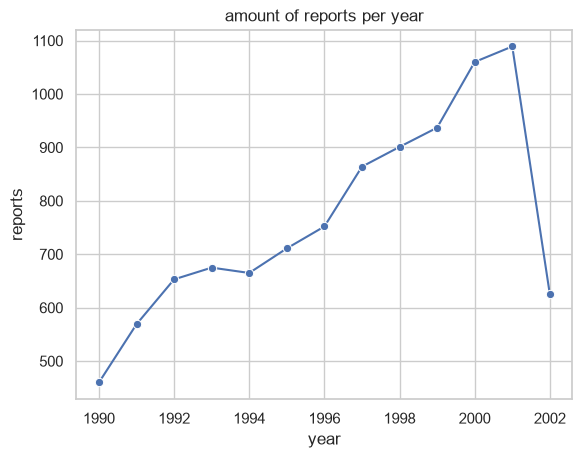

In [161]:
#reports_per_year

fig, ax = plt.subplots()

sns.lineplot(data=reports_per_year, x='Year', y='Reports', marker='o', ax=ax)

ax.set_title('amount of reports per year')
ax.set_xlabel('year')
ax.set_ylabel('reports')

plt.show()

An increasing trend of reports almost every year, except for 1994 and 2002. 2002 marks the latest found year, giving suspicion for when the latest date was when this data was gathered.

### N.2: 

TypeError: Data source must be a DataFrame or Mapping, not <class 'pandas.Series'>.

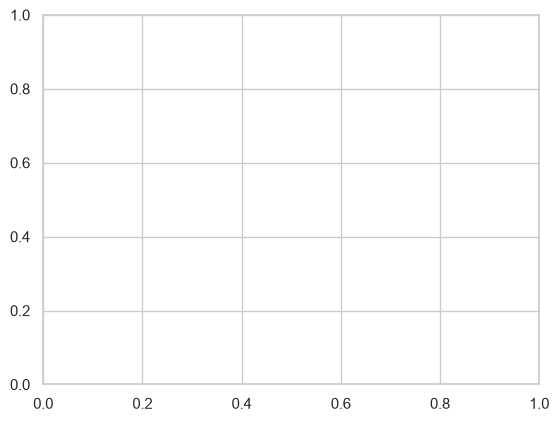

In [162]:
#cost_of_strikes

fig, ax = plt.subplots()

sns.barplot(data=cost_of_strikes, x='Year', y='mean', ax=ax)

ax.set_title('average cost of strike per year')
ax.set_xlabel('year')
ax.set_ylabel('average cost')

plt.tight_layout()
plt.show()


A great increase, drop, increase and drop again between 1995 and 1998. Again, these costs are based on the few entries we *do* have.

### N.3: 

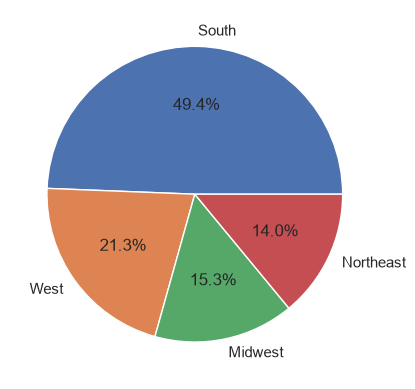

In [ ]:
#strikes_per_region
#https://matplotlib.org/stable/gallery/pie_and_polar_charts/pie_features.html

fig, ax = plt.subplots()

ax.pie(
    strikes_per_region['Strikes'], 
    labels = strikes_per_region['Region'], 
    autopct='%1.1f%%'
)

plt.show()

The majority of strikes have at least been reported in the South, with West being about about a third, or a bit bigger, than the Midwest and Northeast, respectively. 

### N.4: 

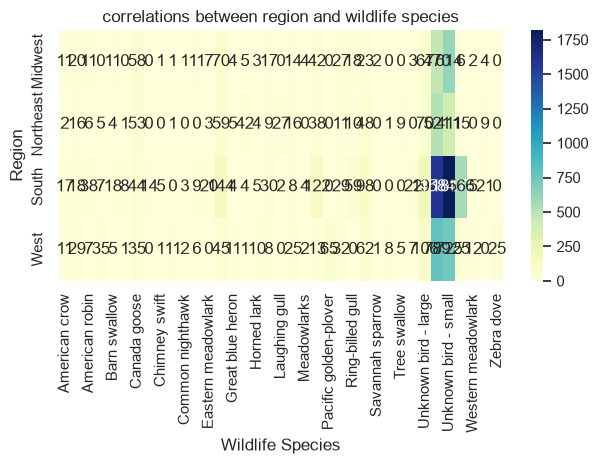

In [ ]:
# #crosstabbed: wildlife species per region

species_region = pd.crosstab(
    birdstrikes['Region'],
    birdstrikes['Wildlife Species']
)

fig, ax = plt.subplots()

sns.heatmap(species_region, annot=True,  fmt="d", cmap='YlGnBu', ax=ax)

ax.set_title('correlations between region and wildlife species')

plt.tight_layout()
plt.show()

While a bit hard to tell the exact numbers from this chart, a great saturation of reported species are Unknown birds, both small and large.

# (9)

Extra data to consider before we move on to point 10 is that 2002 traces entries until 25th of July 2002, its latest recorded date.
It means not the entirety of 2002 has been covered.

In [ ]:
birdstrikes['Flight Date'].sort_values(ascending=False).head(10)

9960   2002-07-25
9959   2002-07-25
9955   2002-07-24
9953   2002-07-24
9954   2002-07-24
9952   2002-07-24
9956   2002-07-24
9957   2002-07-24
9958   2002-07-24
9951   2002-07-23
Name: Flight Date, dtype: datetime64[us]

These questions have their numbers and charts provided mostly through Tasks 6-8.
A sentence is expected for each of these questions, but I will recap and summarize the questions by bringing down the more crucial information here.

1. **Does the number of reports over the years mean more strikes, or more reporting?**
We're seeing an increase - from the beginning (1990) - of 136.7% to 2001 and 35.9% to 2002.
While every entry covers a strike, we can't tell from this dataset alone if these account for all strikes.
It may as well have become of greater interest to report over each year due to more interest in gathering data, or
there have been more flights. This is something we cannot conclude. What we can tell for sure, is that there has been an increase in reporting.
So the latter part of the question is what is being answered here: More reporting.

2. **What does a strike cost, and what does a cost of zero mean?**
Out of the available 194 non-zero costs, we can't conclude directly what a strike costs, especially because these show a great jump in the means, especially between 1995-1998.
We can see that by the 90% quantile, the difference between 1996 and 1995 on Substantial damage is 12362.2 and 396404.2. Since damaged parts and quality isn't specified, and the only thing we could go off of to understand what plane it is would be through Aircraft Make Model.
We cannot conclude what a strike cost due to great unbalance in the cost data.

A cost of zero, like we've discussed before, could mean that there was no actual cost, or that a cost wasn't reported, and so the default value is 0. Yet again something the dataset can't describe for us alone.

3. **Do birdstrikes differ between the regions, and which wildlife species is most commonly involved in the strikes?**




# (10)

Easier to answer this when we know what we don't know.

Source: https://vega.github.io/vega-datasets/datasets/birdstrikes/
Source with contributors more visible: https://github.com/vega/vega-datasets/blob/main/data/birdstrikes.csv
The data can be found on vega-datasets, which itself is comprised by data from the American **FAA Wildlife Strike Database**.
It is released under *Public domain*. 
The origin should make this dataset seem serious and quite trustworthy, and then actual faith that this dataset is trustworthy should be based on 
@domoritz (Dominik Moritz) on GitHub, who put together the data to CSV format.

____

The latest retrieved date is 25th of July 2002. 
...if I have time, I could check the date up until this point BUT on the previous year.